## Analysis of Russia-China border infrastructure and human activity over time

# Install and import modules

In [1]:
%pip install earthengine-api geemap cartopy seaborn pandas matplotlib

import ee
import geemap
import pandas as pd
import matplotlib as plt


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/opt/homebrew/lib/python3.11/site-packages/google/api_core/_python_version_support.py:273: FutureWarning: You are using a Python version (3.11.14) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


### Initialise

In [2]:
ee.Authenticate()
ee.Initialize(project='alphaearth-468711')

# Russia-China border geometry
russiaChinaBorderObject  = geemap.geojson_to_ee('../source-files/china-russia-border.geojson')
russiaChinaBorderGeom = russiaChinaBorderObject.geometry()
russiaChinaBorderGeomBuffered = russiaChinaBorderGeom.buffer(100000) # buffer by 50km

# Night lights

In [3]:
#focus cities along border
cities = ['Heihe', 'Khabarovsk', 'Manzhouli', 'Vladivostok']

# initialise nightlight dataset
nightlights = ee.ImageCollection('NASA/VIIRS/002/VNP46A2')
latest = nightlights.sort('system:time_start', False).first()
print('Latest image date: ' + latest.date().format().getInfo())

nightlights_filtered = nightlights.filter(ee.Filter.date('2017-01-01', latest.date())).select('Gap_Filled_DNB_BRDF_Corrected_NTL')
nighttimeVis = {min: 0.0, max: 1.0};


Latest image date: 2026-11-02T00:00:00


In [4]:
# --- Scaled nightlights (no masking) ------------------------------------
# VNP46A2 NTL bands are stored with a 0.1 scale factor -> nW/cm2/sr
SCALE = 0.1

# Season filter (not a mask - it just selects which nights go into the median).
# Set SEASON = None to use the whole year; winter snow will then inflate
# radiance at this latitude.
SEASON = ee.Filter.calendarRange(5, 9, 'month')   # May-September

def to_ntl(img):
    return (img.select('Gap_Filled_DNB_BRDF_Corrected_NTL')
               .multiply(SCALE)
               .rename('NTL')
               .copyProperties(img, ['system:time_start']))

ntl = nightlights.filter(SEASON) if SEASON else nightlights
ntl = ntl.map(to_ntl)

def composite(start, end):
    return ntl.filter(ee.Filter.date(start, end)).median().rename('NTL')

In [5]:
# --- Baseline vs recent -------------------------------------------------
baseNTL   = composite('2017-01-01', '2018-01-01')
recentNTL = composite('2025-01-01', '2026-01-01')

abs_change = recentNTL.subtract(baseNTL).rename('abs_change')

# Denominator floor (nW/cm2/sr). Not a mask - nothing is hidden - it just stops
# near-zero background pixels from turning sensor noise into +/-1000%.
# Set DENOM_FLOOR = 0 for the raw ratio.
DENOM_FLOOR = 0.5

pct_change = (recentNTL.subtract(baseNTL)
                .divide(baseNTL.max(DENOM_FLOOR))
                .multiply(100)
                .rename('pct_change'))

buf = russiaChinaBorderGeomBuffered

In [6]:
# --- Map ----------------------------------------------------------------
# Log stretch on the reference layer: settlement radiance spans 3+ orders of
# magnitude, so a linear stretch shows either cities or villages, never both.
log_recent = recentNTL.max(0.05).log10()
log_base   = baseNTL.max(0.05).log10()

ntlVis    = {'min': -1.3, 'max': 1.7, 'palette': ["#2c0b54",'#3b0f70','#8c2981','#de4968','#fe9f6d','#fcfdbf']}
changeVis = {'min': -100, 'max': 100, 'palette': ['#2166ac', '#f7f7f7', '#b2182b']}
absVis    = {'min': -5,   'max': 5,   'palette': ['#2166ac', '#f7f7f7', '#b2182b']}

NightlightsMap = geemap.Map(center=[48, 128], zoom=5)

# English-language basemap. The default OSM basemap labels places in the local
# script (Cyrillic / Chinese); Google's tiles honour an hl= language parameter.
NightlightsMap.clear_layers()
NightlightsMap.add_tile_layer(
    url='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}&hl=en',
    name='Google Roads (EN)',
    attribution='Google',
)

NightlightsMap.addLayer(log_recent.clip(buf),  ntlVis,    'NTL 2025 (log10)')
NightlightsMap.addLayer(log_base.clip(buf),  ntlVis,    'NTL 2017 (log10)', False)
NightlightsMap.addLayer(abs_change.clip(buf),  absVis,    'Absolute NTL change', False)
NightlightsMap.addLayer(pct_change.clip(buf),  changeVis, '% NTL change 2017 -> 2025', True)
NightlightsMap.addLayer(buf, {}, 'Border buffer (50km)', False)
NightlightsMap.addLayer(russiaChinaBorderGeom, {}, 'Border', True)
NightlightsMap

Map(center=[48, 128], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tra…

### Clip nightlights around selected cities

In [ ]:
import os, json, requests

EXPORT_DIR = '../exports'
os.makedirs(EXPORT_DIR, exist_ok=True)

RADIUS_M = 50000     # 50 km
EXPORT_SCALE = 463.83  # native VNP46A2 pixel size (~15 arc-sec), metres

# City coordinates from the populated-places source file
with open('../source-files/populated-places-clipped.geojson', encoding='utf-8') as f:
    places = json.load(f)

city_pts = {}
for feat in places['features']:
    name = feat['properties']['NAME']
    if name in cities:
        city_pts[name] = feat['geometry']['coordinates']  # [lon, lat]
missing = set(cities) - set(city_pts)
assert not missing, f'Not found in geojson: {missing}'

layers = {'NTL_2025': recentNTL, 'NTL_2017': baseNTL}
png_vis = {'min': ntlVis['min'], 'max': ntlVis['max'], 'palette': ntlVis['palette']}

for city in cities:
    lon, lat = city_pts[city]
    region = ee.Geometry.Point([lon, lat]).buffer(RADIUS_M)
    box = region.bounds()
    for lname, img in layers.items():
        clipped = img.clip(region)

        # GeoTIFF: raw radiance (nW/cm2/sr)
        tif = f'{EXPORT_DIR}/{city}_{lname}.tif'
        geemap.ee_export_image(
            clipped, filename=tif, scale=EXPORT_SCALE, region=box,
            crs='EPSG:3857', file_per_band=False)

        # PNG: log10 stretch, same as map; pixels outside the 50 km circle are transparent
        png = f'{EXPORT_DIR}/{city}_{lname}.png'
        url = (clipped.max(0.05).log10()
               .visualize(**png_vis)
               .getThumbURL({'region': box, 'dimensions': 1024, 'format': 'png'}))
        r = requests.get(url, timeout=300)
        r.raise_for_status()
        with open(png, 'wb') as f:
            f.write(r.content)

        print('saved', tif, '|', png)

print(sorted(os.listdir(EXPORT_DIR)))


Generating URL ...
Please wait ...
Data downloaded to /Users/josephclark/Documents/Birkbeck/Dissertation/python-files/exports/Heihe_NTL_2025.tif
saved ../exports/Heihe_NTL_2025.tif | ../exports/Heihe_NTL_2025.png
Generating URL ...
Please wait ...
Data downloaded to /Users/josephclark/Documents/Birkbeck/Dissertation/python-files/exports/Heihe_NTL_2017.tif
saved ../exports/Heihe_NTL_2017.tif | ../exports/Heihe_NTL_2017.png
Generating URL ...
Please wait ...
Data downloaded to /Users/josephclark/Documents/Birkbeck/Dissertation/python-files/exports/Khabarovsk_NTL_2025.tif
saved ../exports/Khabarovsk_NTL_2025.tif | ../exports/Khabarovsk_NTL_2025.png
Generating URL ...
Please wait ...
Data downloaded to /Users/josephclark/Documents/Birkbeck/Dissertation/python-files/exports/Khabarovsk_NTL_2017.tif
saved ../exports/Khabarovsk_NTL_2017.tif | ../exports/Khabarovsk_NTL_2017.png
Generating URL ...
Please wait ...
Data downloaded to /Users/josephclark/Documents/Birkbeck/Dissertation/python-files/

# Nightlight time series, selected cities (2017 onward)
Monthly mean VNP46A2 radiance (nW/cm2/sr) inside a 50 km circle around each city, from January 2017 to the latest image. Full year (no season filter), so the series includes winter snow effects; the 12-month rolling mean smooths these out.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

RSCALE = 463.83                      # native VNP46A2 pixel size (m)
END_MONTH = ee.Date(latest.date()).format('YYYY-MM').getInfo()
months = pd.period_range(start='2017-01', end=END_MONTH, freq='M')

ntl_all = nightlights.map(to_ntl)    # full year, not the May-Sep SEASON subset
cityFC = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point(city_pts[c]).buffer(RADIUS_M), {'city': c})
    for c in cities])

rows = []
for m in months:
    start = ee.Date(m.start_time.strftime('%Y-%m-%d'))
    month_img = ntl_all.filterDate(start, start.advance(1, 'month')).mean().rename('NTL')
    res = month_img.reduceRegions(collection=cityFC, reducer=ee.Reducer.mean(), scale=RSCALE).getInfo()
    if not rows:   # one-off diagnostic: shows the raw property names returned
        print('sample properties:', res['features'][0]['properties'])
    for f in res['features']:
        props = f['properties']
        val = next((v for k, v in props.items()
                    if k != 'city' and isinstance(v, (int, float))), None)
        rows.append({'month': m.start_time, 'city': props['city'], 'radiance': val})
    print(m, end=' ')
print()

ts = (pd.DataFrame(rows)
        .pivot(index='month', columns='city', values='radiance')[cities])
roll = ts.rolling(12, min_periods=12).mean()
print(f'{len(ts)} months, {ts.index.min():%Y-%m} to {ts.index.max():%Y-%m}')
ts.round(3).tail()


sample properties: {'city': 'Heihe', 'mean': 0.1870612315178664}
2017-01 2017-02 2017-03 2017-04 2017-05 2017-06 2017-07 2017-08 2017-09 2017-10 2017-11 2017-12 2018-01 2018-02 2018-03 2018-04 2018-05 2018-06 2018-07 2018-08 2018-09 2018-10 2018-11 2018-12 2019-01 2019-02 2019-03 2019-04 2019-05 2019-06 2019-07 2019-08 2019-09 2019-10 2019-11 2019-12 2020-01 2020-02 2020-03 2020-04 2020-05 2020-06 2020-07 2020-08 2020-09 2020-10 2020-11 2020-12 2021-01 2021-02 2021-03 2021-04 2021-05 2021-06 2021-07 2021-08 2021-09 2021-10 2021-11 2021-12 2022-01 2022-02 2022-03 2022-04 2022-05 2022-06 2022-07 2022-08 2022-09 2022-10 2022-11 2022-12 2023-01 2023-02 2023-03 2023-04 2023-05 2023-06 2023-07 2023-08 2023-09 2023-10 2023-11 2023-12 2024-01 2024-02 2024-03 2024-04 2024-05 2024-06 2024-07 2024-08 2024-09 2024-10 2024-11 2024-12 2025-01 2025-02 2025-03 2025-04 2025-05 2025-06 2025-07 2025-08 2025-09 2025-10 2025-11 2025-12 2026-01 2026-02 2026-03 2026-04 2026-05 2026-06 2026-07 2026-08 2026-09

city,Heihe,Khabarovsk,Manzhouli,Vladivostok
month,,,,
2026-07-01,0.086,0.173,0.035,0.166
2026-08-01,0.134,0.143,0.042,0.163
2026-09-01,0.195,0.169,0.042,0.166
2026-10-01,0.232,0.205,0.040,0.164
2026-11-01,0.296,0.225,0.037,0.187


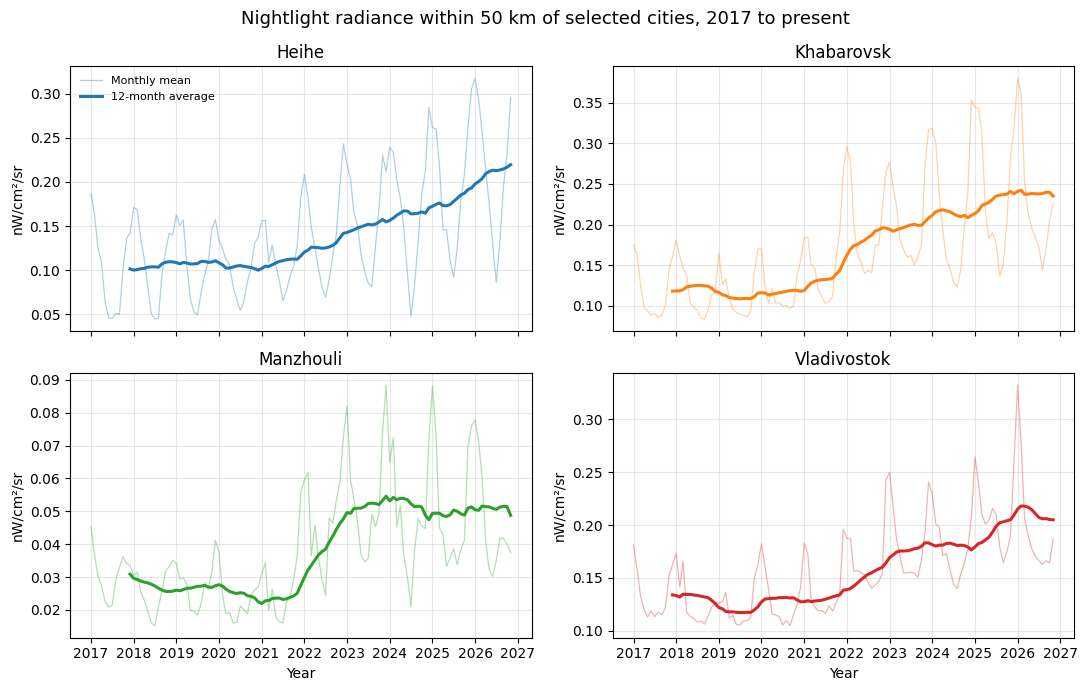

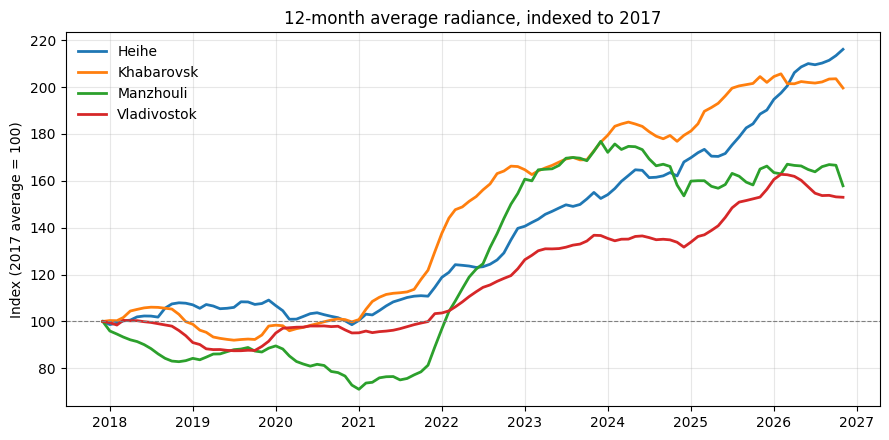

In [11]:
colours = {'Heihe': '#1f77b4', 'Khabarovsk': '#ff7f0e', 'Manzhouli': '#2ca02c', 'Vladivostok': '#d62728'}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, city in zip(axes.flat, cities):
    ax.plot(ts.index, ts[city], color=colours[city], alpha=0.35, lw=0.9, label='Monthly mean')
    ax.plot(roll.index, roll[city], color=colours[city], lw=2.2, label='12-month average')
    ax.set_title(city)
    ax.grid(alpha=.3)
    ax.set_ylabel('nW/cm²/sr')
for ax in axes[-1]:
    ax.set_xlabel('Year')
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle('Nightlight radiance within 50 km of selected cities, 2017 to present', fontsize=13)
fig.tight_layout()
fig.savefig('../exports/nightlights_timeseries.png', dpi=150)
plt.show()

# Same series indexed to the 2017 average (= 100), all cities on one axes
base = ts[ts.index.year == 2017].mean()
idx = roll / base * 100
fig2, ax2 = plt.subplots(figsize=(9, 4.5))
for city in cities:
    ax2.plot(idx.index, idx[city], color=colours[city], lw=2, label=city)
ax2.axhline(100, color='grey', lw=0.8, ls='--')
ax2.set_ylabel('Index (2017 average = 100)')
ax2.set_title('12-month average radiance, indexed to 2017')
ax2.grid(alpha=.3)
ax2.legend(frameon=False)
fig2.tight_layout()
fig2.savefig('../exports/nightlights_timeseries_index.png', dpi=150)
plt.show()


## Alpha earth index